In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate,
    GridSearchCV, RandomizedSearchCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
)
from sklearn.metrics import f1_score, roc_auc_score

df = pd.read_csv('../data/heart_clean.csv')

X = df.drop(columns=['DEATH_EVENT'])
y = df['DEATH_EVENT']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

cont_cols = [
    'age', 'creatinine_phosphokinase', 'ejection_fraction',
    'platelets', 'serum_creatinine', 'serum_sodium'
]

def make_pipeline(model):
    pre = ColumnTransformer(
        [('scale', StandardScaler(), cont_cols)],
        remainder='passthrough'
    )
    return Pipeline([
        ('pre', pre),
        ('model', model)
    ])

models = {
    'Logistic Regression': make_pipeline(
        LogisticRegression(max_iter=1000)
    ),
    'LDA': make_pipeline(LinearDiscriminantAnalysis()),
    'QDA': make_pipeline(QuadraticDiscriminantAnalysis())
}

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Models prepared:", list(models.keys()))

Training features: (239, 11)
Testing features: (60, 11)
Models prepared: ['Logistic Regression', 'LDA', 'QDA']


In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []

for name, pipe in models.items():
    res = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring=['f1', 'roc_auc'],
        return_train_score=True
    )

    rows.append([
        name,
        res['test_f1'].mean(),
        res['test_f1'].std(),
        res['test_roc_auc'].mean(),
        res['test_roc_auc'].std(),
        res['train_roc_auc'].mean(),
        res['train_roc_auc'].mean() - res['test_roc_auc'].mean()
    ])

cv_results = pd.DataFrame(
    rows,
    columns=[
        'Model', 'CV F1', 'F1 std', 'CV AUC', 'AUC std',
        'Train AUC', 'Train-CV AUC gap'
    ]
).set_index('Model')

cv_results.round(3)

,CV F1,F1 std,CV AUC,AUC std,Train AUC,Train-CV AUC gap
Model,,,,,,
Logistic Regression,0.530,0.065,0.797,0.051,0.828,0.031
LDA,0.524,0.062,0.800,0.051,0.828,0.028
QDA,0.469,0.092,0.721,0.023,0.874,0.152


In [4]:
grid = GridSearchCV(
    make_pipeline(LogisticRegression(max_iter=1000)),
    param_grid={'model__C': [0.01, 0.1, 1, 10, 100]},
    scoring='roc_auc',
    cv=cv
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best cross-validation AUC:", round(grid.best_score_, 3))

Best parameters: {'model__C': 0.1}
Best cross-validation AUC: 0.799


In [5]:
rand = RandomizedSearchCV(
    make_pipeline(QuadraticDiscriminantAnalysis()),
    param_distributions={
        'model__reg_param': np.linspace(0, 1, 50)
    },
    n_iter=15,
    scoring='roc_auc',
    cv=cv,
    random_state=42
)

rand.fit(X_train, y_train)

print("Best parameters:", rand.best_params_)
print("Best cross-validation AUC:", round(rand.best_score_, 3))

Best parameters: {'model__reg_param': np.float64(0.7551020408163265)}
Best cross-validation AUC: 0.791


In [6]:
fitted = {
    name: pipe.fit(X_train, y_train)
    for name, pipe in models.items()
}

tuned = {
    'Logistic Regression (tuned)': grid.best_estimator_,
    'QDA (tuned)': rand.best_estimator_
}

rows = []

for name, model in {**fitted, **tuned}.items():
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]

    rows.append([
        name,
        f1_score(y_test, pred),
        roc_auc_score(y_test, proba)
    ])

test_table = pd.DataFrame(
    rows,
    columns=['Model', 'Test F1', 'Test AUC']
).set_index('Model')

test_table.round(3)

,Test F1,Test AUC
Model,,
Logistic Regression,0.485,0.743
LDA,0.485,0.727
QDA,0.471,0.677
Logistic Regression (tuned),0.414,0.761
QDA (tuned),0.500,0.782


In [7]:
final = cv_results[
    ['CV F1', 'CV AUC', 'Train-CV AUC gap']
].join(
    test_table.loc[
        ['Logistic Regression', 'LDA', 'QDA']
    ]
)

final.round(3)

,CV F1,CV AUC,Train-CV AUC gap,Test F1,Test AUC
Model,,,,,
Logistic Regression,0.530,0.797,0.031,0.485,0.743
LDA,0.524,0.800,0.028,0.485,0.727
QDA,0.469,0.721,0.152,0.471,0.677


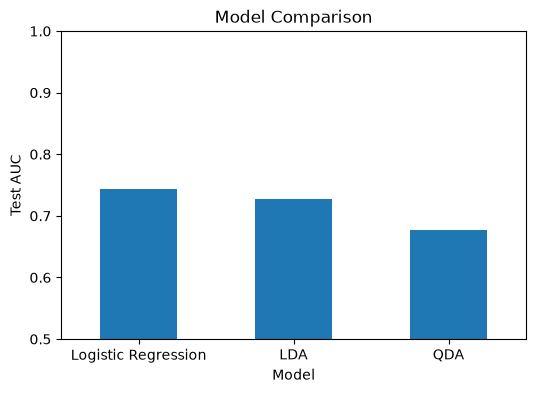

In [8]:
final['Test AUC'].plot.bar(
    figsize=(6, 4),
    ylim=(0.5, 1)
)

plt.ylabel('Test AUC')
plt.title('Model Comparison')
plt.xticks(rotation=0)
plt.show()

In [9]:
final.round(3).to_csv('../report/final_comparison.csv')

print("Final comparison saved successfully!")

Final comparison saved successfully!
